# Implementación del TFIM: Trotter, fidelidad, ED y VQE

El modelo de Ising con campo transverso (TFIM) en una cadena periódica es

$$
H=-J\sum_{i=0}^{N-1}Z_iZ_{i+1}-h\sum_{i=0}^{N-1}X_i,
\qquad Z_N=Z_0.
$$

La interacción $J$ favorece el orden ferromagnético en $Z$, mientras que el
campo $h$ favorece la polarización en $X$. En el límite termodinámico ambas
tendencias compiten en $h/J=1$.

Este notebook sigue los cinco objetivos del reto:

1. evolución temporal trotterizada y degradación con el tamaño;
2. dinámica de $\langle Z\rangle$ y $\langle Z_iZ_j\rangle$;
3. comparación de los regímenes $h/J\in\{0.5,1,2\}$;
4. validación por diagonalización exacta (ED) con 6 qubits;
5. un barrido VQE con 6 espines y dos semillas por campo.

Todas las funciones están en `funciones_ising_hackathon.py`. El notebook
conserva solamente parámetros, experimentos, tablas e interpretación.

## Resultados consolidados — 15 de noviembre de 2026

La actualización completa y las decisiones propuestas por Benjamín Sánchez Hernández están en [la bitácora experimental](../reports/bitacora_tfim_2026-11-15.md). Los diez campos tienen resultados finales guardados con fidelidad superior al 99 %.

| h/J | Fidelidad final | Paridad | Error absoluto de energía | Pasos del resultado | Inicio |
|---:|---:|---:|---:|---:|:--|
| 0.2 | 0.999788 | 0.999857 | 0.001008 | 800 | semilla 3; dos reinicios |
| 0.4 | 0.998895 | 0.999972 | 0.003997 | 800 | semilla 42; dos reinicios |
| 0.6 | 0.998948 | 0.999992 | 0.005217 | 800 | semilla 42; dos reinicios |
| 0.8 | 0.998505 | 0.999981 | 0.009777 | 800 | parámetros de 0.6 |
| 1.0 | 0.997967 | 0.999999 | 0.014043 | 100 | parámetros de 0.8 |
| 1.2 | 0.998219 | 0.999999 | 0.012284 | 100 | parámetros de 1.0 |
| 1.4 | 0.998818 | 1.000000 | 0.008603 | 100 | parámetros de 1.2 |
| 1.6 | 0.999274 | 1.000000 | 0.005686 | 100 | parámetros de 1.4 |
| 1.8 | 0.999561 | 1.000000 | 0.003768 | 100 | parámetros de 1.6 |
| 2.0 | 0.999728 | 1.000000 | 0.002562 | 100 | parámetros de 1.8 |

La tabla combina los reinicios independientes de 0.2–0.6, la prueba puntual 0.6 → 0.8 y la continuación adaptativa 0.8 → 2.0. Las secciones posteriores conservan los experimentos en orden y distinguen los resultados históricos de los finales. Las cifras completas y su procedencia están en [el CSV consolidado](../reports/tfim_vqe_resultados_finales.csv).

Se publican las tablas CSV y las figuras. Los NPZ de estados, parámetros e historiales se generan localmente al ejecutar las celdas de entrenamiento de las secciones 5 y 7 antes de reproducir los scripts.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "src" / "tfim"))

from funciones_ising_hackathon import *

estilo_graficas_tfim()
np.set_printoptions(precision=5, suppress=True)


## Parámetros reproducibles

Usamos frontera periódica y el estado producto

$$
|\psi(0)\rangle=|0\rangle^{\otimes N}.
$$

Este estado tiene $\langle M_z\rangle=1$ y
$\langle C_{ZZ}\rangle=1$. La ED dinámica y el VQE usan $N=6$. El VQE prueba
dos semillas por campo (`3` y `42`) y conserva el resultado de menor costo penalizado.
El escalado Trotter se ejecuta entre 4 y 12 espines.

In [2]:
J = 1.0
campos = (0.5, 1.0, 2.0)
campos_vqe = tuple(np.round(np.arange(0.2, 2.01, 0.2), 1))
n_ed = 6
n_vqe = 6
semillas_vqe = (3, 42)
paridad_objetivo_vqe = 1
peso_paridad_vqe = abs(J)  # lambda = J = 1 en este barrido
r_dinamica = 20
tiempos = np.linspace(0.0, 10.0, 62)

print(f"ED dinámica: N={n_ed}")
print(f"VQE: N={n_vqe}, semillas={semillas_vqe}")
print(f"Paridad objetivo: {paridad_objetivo_vqe:+d}, lambda={peso_paridad_vqe}")
print(f"Campos de dinámica y ED: {campos}")
print(f"Barrido VQE ({len(campos_vqe)} puntos): {campos_vqe}")
print(f"Dinámica: {len(tiempos)} tiempos, r={r_dinamica}")


ED dinámica: N=6
VQE: N=6, semillas=(3, 42)
Paridad objetivo: +1, lambda=1.0
Campos de dinámica y ED: (0.5, 1.0, 2.0)
Barrido VQE (10 puntos): (np.float64(0.2), np.float64(0.4), np.float64(0.6), np.float64(0.8), np.float64(1.0), np.float64(1.2), np.float64(1.4), np.float64(1.6), np.float64(1.8), np.float64(2.0))
Dinámica: 62 tiempos, r=20


## Herramientas numéricas

- **Qiskit:** construye los circuitos de Trotter, simula sus vectores de estado y representa los operadores del TFIM. También permite comparar la evolución contra ED para $N=6$.
- **PennyLane:** define el circuito variacional diferenciable del VQE y calcula gradientes para que Adam minimice la energía más la penalización de paridad.
- **Diagonalización exacta (ED):** proporciona la referencia clásica de energía, estado y observables. Su costo crece como $2^N$, por eso se usa solamente con 6 espines.

La **trotterización** aproxima una evolución difícil mediante pasos cortos de términos implementables. El **VQE** es un ciclo híbrido: un circuito prepara $|\psi(\theta)\rangle$ y un optimizador clásico minimiza

$$
E(\theta)=\langle\psi(\theta)|H|\psi(\theta)\rangle\geq E_0,
\qquad
\mathcal L_+(\theta)=E(\theta)+\frac{\lambda}{2}(1-\langle P\rangle_\theta).
$$

Ambas herramientas resuelven preguntas distintas: Trotter estudia dinámica temporal; VQE aproxima el estado fundamental.

## 1. Evolución de Trotter y convergencia

Separamos $H=H_{ZZ}+H_X$ y usamos Trotter de primer orden:

$$
e^{-iH\tau}\approx
\left(e^{-iH_{ZZ}\Delta\tau}e^{-iH_X\Delta\tau}\right)^r,
\qquad \Delta\tau=\frac{\tau}{r}.
$$

Como $H_{ZZ}$ y $H_X$ no conmutan, reducir $\Delta\tau$ debe aumentar la
fidelidad

$$
F=|\langle\psi_{\mathrm{ED}}|\psi_{\mathrm{Trotter}}\rangle|^2.
$$

In [14]:
circuito_ejemplo = circuito_tfim_trotter_cerrado(
    J=J, h=J, n_q=n_ed, r=4, t=1.0
)
print("Ejemplo N=6, h/J=1, r=4")
print("Δτ =", 1.0 / 4)
print("Profundidad =", circuito_ejemplo.depth())
print("Compuertas =", circuito_ejemplo.size())

Ejemplo N=6, h/J=1, r=4
Δτ = 0.25
Profundidad = 28
Compuertas = 48


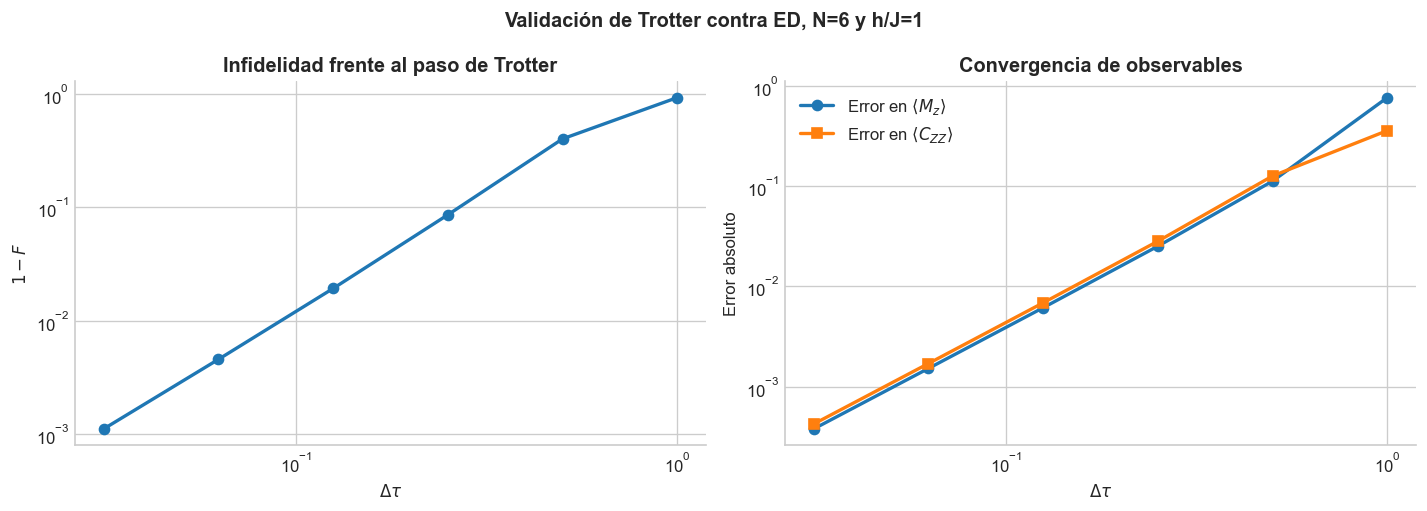

In [15]:
valores_r = np.array([1, 2, 4, 8, 16, 32])
convergencia = convergencia_trotter_tfim(
    valores_r, J=J, h=J, n_q=n_ed, t=1.0
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
axes[0].loglog(
    convergencia["dt"],
    1 - convergencia["fidelidad"],
    "o-", lw=2,
)
axes[0].set(
    xlabel=r"$\Delta\tau$",
    ylabel=r"$1-F$",
    title="Infidelidad frente al paso de Trotter",
)

axes[1].loglog(
    convergencia["dt"], convergencia["error_mz"],
    "o-", lw=2, label=r"Error en $\langle M_z\rangle$",
)
axes[1].loglog(
    convergencia["dt"], convergencia["error_czz"],
    "s-", lw=2, label=r"Error en $\langle C_{ZZ}\rangle$",
)
axes[1].set(
    xlabel=r"$\Delta\tau$",
    ylabel="Error absoluto",
    title="Convergencia de observables",
)
axes[1].legend()
fig.suptitle("Validación de Trotter contra ED, N=6 y h/J=1", fontweight="bold")
fig.tight_layout()
plt.show()

La fidelidad cuantifica el error del estado completo; los errores de
observables indican cuánto de ese error afecta las cantidades físicas que
reportamos. Ambas pruebas son necesarias: un observable aislado puede coincidir
aunque el estado global ya se haya degradado.

### Degradación con el tamaño: 4–12 espines

Para tamaños mayores que la ED práctica, comparamos las aproximaciones con $r$
y $2r$. Si ambas dejan de coincidir, el paso elegido ya no está convergido.
También registramos profundidad, número de compuertas, tiempo local y memoria
del vector de estado. La misma función acepta después tamaños de hasta 20.

In [16]:
escalado = escalado_trotter_tfim(
    tamanos=(4, 6, 8, 10, 12),
    J=J, h=J, r=4, t=1.0,
)

lineas = [
    "| $N$ | Profundidad | Compuertas | $F(r,2r)$ | Tiempo (s) | Memoria (MB) |",
    "|---:|---:|---:|---:|---:|---:|",
]
for fila in escalado:
    lineas.append(
        f"| {fila['n_q']} | {fila['profundidad']} | {fila['compuertas']} | "
        f"{fila['fidelidad_r_2r']:.6f} | {fila['tiempo_s']:.4f} | "
        f"{fila['memoria_estado_mb']:.4f} |"
    )
display(Markdown("\n".join(lineas)))

| $N$ | Profundidad | Compuertas | $F(r,2r)$ | Tiempo (s) | Memoria (MB) |
|---:|---:|---:|---:|---:|---:|
| 4 | 20 | 32 | 0.977711 | 0.0065 | 0.0002 |
| 6 | 28 | 48 | 0.974242 | 0.0059 | 0.0010 |
| 8 | 36 | 64 | 0.965857 | 0.0088 | 0.0039 |
| 10 | 44 | 80 | 0.957497 | 0.0132 | 0.0156 |
| 12 | 52 | 96 | 0.949215 | 0.0173 | 0.0625 |

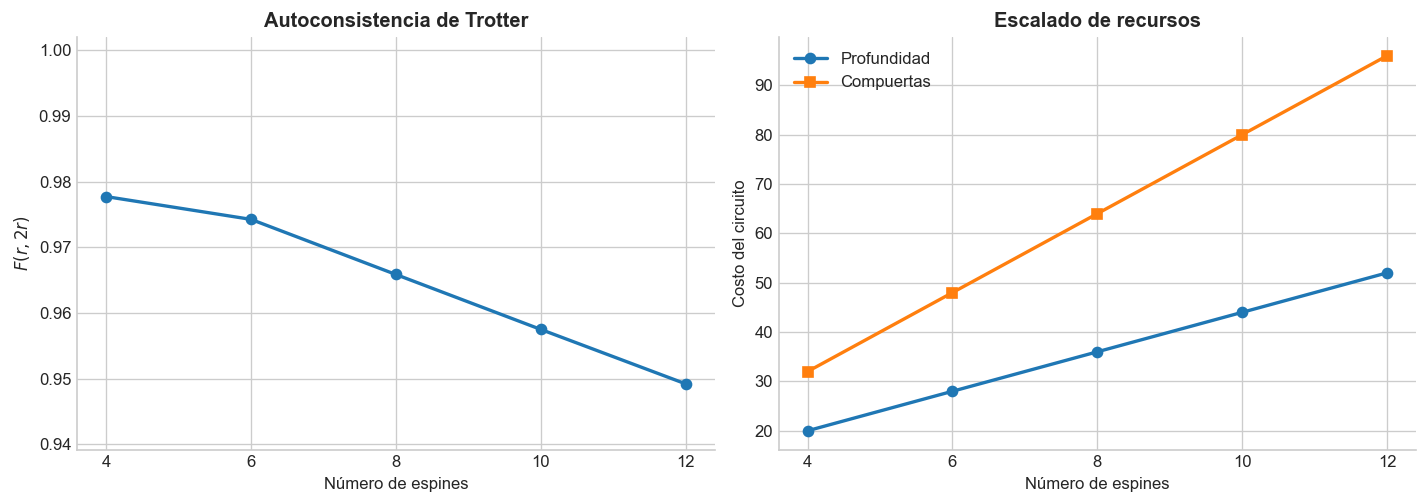

In [17]:
n_escalado = np.array([fila["n_q"] for fila in escalado])
f_escalado = np.array([fila["fidelidad_r_2r"] for fila in escalado])
profundidad = np.array([fila["profundidad"] for fila in escalado])
compuertas = np.array([fila["compuertas"] for fila in escalado])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
axes[0].plot(n_escalado, f_escalado, "o-", lw=2)
axes[0].set(
    xlabel="Número de espines",
    ylabel=r"$F(r,2r)$",
    title="Autoconsistencia de Trotter",
    xticks=n_escalado,
)
axes[0].set_ylim(min(f_escalado) - 0.01, 1.002)

axes[1].plot(n_escalado, profundidad, "o-", lw=2, label="Profundidad")
axes[1].plot(n_escalado, compuertas, "s-", lw=2, label="Compuertas")
axes[1].set(
    xlabel="Número de espines",
    ylabel="Costo del circuito",
    title="Escalado de recursos",
    xticks=n_escalado,
)
axes[1].legend()
fig.tight_layout()
plt.show()

Sí se observa degradación: con $r$ fijo, cada paso contiene más
términos y la infidelidad acumulada aumenta con $N$. Además, profundidad y
compuertas crecen linealmente, mientras la memoria de un simulador de
vector de estado crece como $2^N$. Esta corrida llega a $N=12$; extenderla
a $N=20$ requiere cambiar únicamente la lista `tamanos`.

## 2. Dinámica de $\langle Z\rangle$ y $\langle Z_iZ_j\rangle$

Medimos los promedios

$$
M_z=\frac{1}{N}\sum_i Z_i,
\qquad
C_{ZZ}=\frac{1}{N}\sum_i Z_iZ_{i+1}.
$$

Las líneas continuas son Trotter y las discontinuas ED. La fidelidad se evalúa
en cada tiempo, no solo al final.

In [18]:
dinamicas = {
    razon: dinamica_tfim_comparada(
        J=J, h=razon * J, n_q=n_ed,
        r=r_dinamica, tiempos=tiempos,
    )
    for razon in campos
}

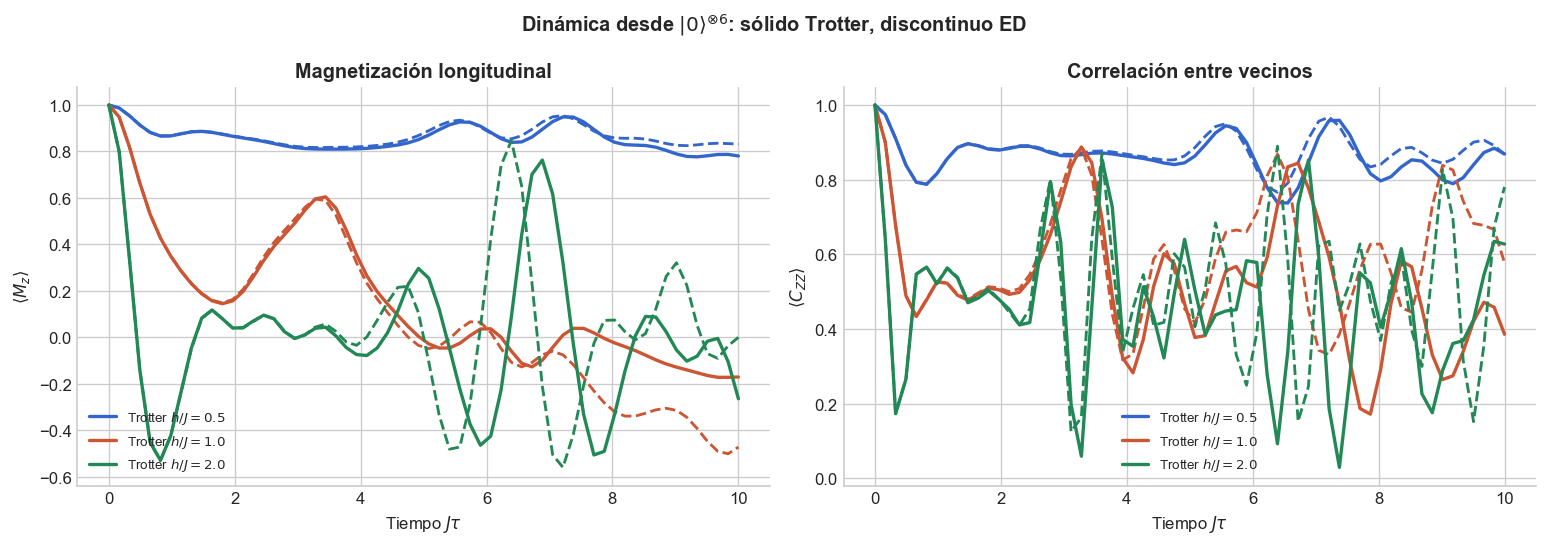

In [19]:
colores = {0.5: "#3366cc", 1.0: "#cc5533", 2.0: "#228855"}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for razon, datos in dinamicas.items():
    color = colores[razon]
    axes[0].plot(
        datos["tiempos"], datos["mz_trotter"],
        color=color, lw=2, label=rf"Trotter $h/J={razon}$",
    )
    axes[0].plot(
        datos["tiempos"], datos["mz_exacta"],
        color=color, ls="--", lw=1.7,
    )
    axes[1].plot(
        datos["tiempos"], datos["czz_trotter"],
        color=color, lw=2, label=rf"Trotter $h/J={razon}$",
    )
    axes[1].plot(
        datos["tiempos"], datos["czz_exacta"],
        color=color, ls="--", lw=1.7,
    )

axes[0].set(
    xlabel=r"Tiempo $J\tau$",
    ylabel=r"$\langle M_z\rangle$",
    title="Magnetización longitudinal",
)
axes[1].set(
    xlabel=r"Tiempo $J\tau$",
    ylabel=r"$\langle C_{ZZ}\rangle$",
    title="Correlación entre vecinos",
)
for ax in axes:
    ax.legend(fontsize=8)
fig.suptitle(r"Dinámica desde $|0\rangle^{\otimes 6}$: sólido Trotter, discontinuo ED", fontweight="bold")
fig.tight_layout()
plt.show()

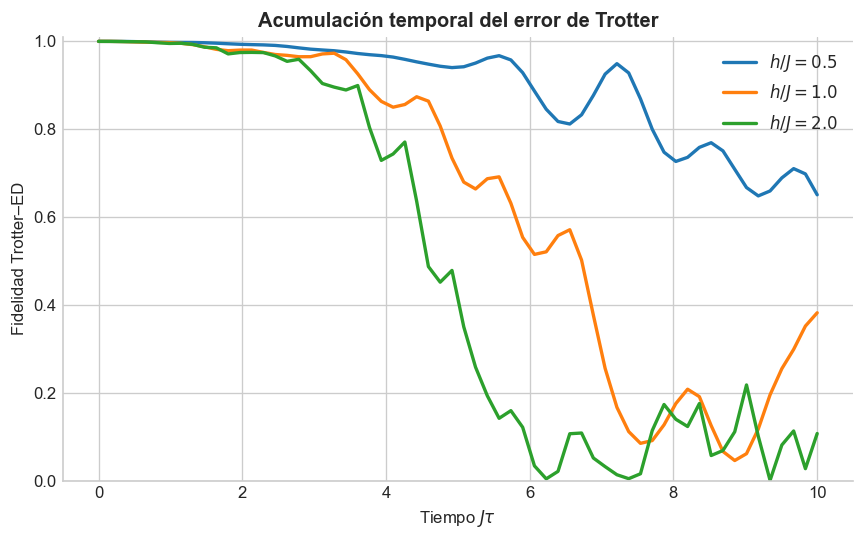

| $h/J$ | Fidelidad mínima | RMSE $M_z$ | RMSE $C_{ZZ}$ |
|---:|---:|---:|---:|
| 0.5 | 0.648105 | 2.065e-02 | 2.672e-02 |
| 1.0 | 0.045473 | 1.370e-01 | 1.890e-01 |
| 2.0 | 0.000295 | 3.533e-01 | 2.243e-01 |

In [20]:
fig, ax = plt.subplots()
for razon, datos in dinamicas.items():
    ax.plot(
        datos["tiempos"], datos["fidelidad"],
        lw=2, label=rf"$h/J={razon}$",
    )
ax.set(
    xlabel=r"Tiempo $J\tau$",
    ylabel="Fidelidad Trotter–ED",
    title="Acumulación temporal del error de Trotter",
)
ax.set_ylim(0, 1.01)
ax.legend()
plt.show()

lineas = [
    "| $h/J$ | Fidelidad mínima | RMSE $M_z$ | RMSE $C_{ZZ}$ |",
    "|---:|---:|---:|---:|",
]
for razon, datos in dinamicas.items():
    rmse_mz = np.sqrt(np.mean((datos["mz_trotter"] - datos["mz_exacta"]) ** 2))
    rmse_czz = np.sqrt(np.mean((datos["czz_trotter"] - datos["czz_exacta"]) ** 2))
    lineas.append(
        f"| {razon:.1f} | {datos['fidelidad'].min():.6f} | "
        f"{rmse_mz:.3e} | {rmse_czz:.3e} |"
    )
display(Markdown("\n".join(lineas)))

## 3. Barrido de $h/J$ y señal de la transición

Para un estado fundamental finito y simétrico,
$\langle M_z\rangle\approx0$ incluso en el régimen ferromagnético. Por ello
usamos $\sqrt{\langle M_z^2\rangle}$ como parámetro de orden longitudinal y
$\langle M_x\rangle$ como magnetización transversal.

En $N=6$ no existe una singularidad: la transición de $h/J=1$ aparece
redondeada por tamaño finito.

| $h/J$ | $E_0/N$ | $\langle M_z\rangle$ | $\sqrt{\langle M_z^2\rangle}$ | $\langle M_x\rangle$ | $C_{ZZ}$ |
|---:|---:|---:|---:|---:|---:|
| 0.5 | -1.064116 | 9.26e-13 | 0.969914 | 0.265198 | 0.931517 |
| 1.0 | -1.287901 | -2.99e-15 | 0.813220 | 0.643951 | 0.643951 |
| 2.0 | -2.128232 | 4.74e-17 | 0.554173 | 0.931517 | 0.265198 |

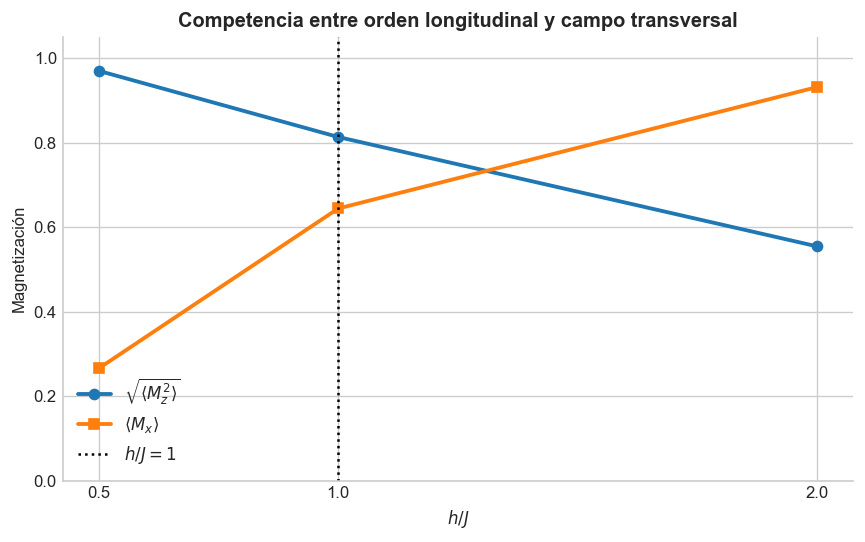

In [21]:
fase_ed = barrido_fase_ed_tfim(
    valores_h_sobre_J=campos, J=J, n_q=n_ed
)

lineas = [
    r"| $h/J$ | $E_0/N$ | $\langle M_z\rangle$ | "
    r"$\sqrt{\langle M_z^2\rangle}$ | $\langle M_x\rangle$ | $C_{ZZ}$ |",
    "|---:|---:|---:|---:|---:|---:|",
]
for fila in fase_ed:
    lineas.append(
        f"| {fila['h/J']:.1f} | {fila['E0/N']:.6f} | {fila['Mz']:.2e} | "
        f"{fila['sqrt_Mz2']:.6f} | {fila['Mx']:.6f} | {fila['Czz']:.6f} |"
    )
display(Markdown("\n".join(lineas)))

x_fase = np.array([fila["h/J"] for fila in fase_ed])
mz_fase = np.array([fila["sqrt_Mz2"] for fila in fase_ed])
mx_fase = np.array([fila["Mx"] for fila in fase_ed])

fig, ax = plt.subplots()
ax.plot(x_fase, mz_fase, "o-", lw=2.3, label=r"$\sqrt{\langle M_z^2\rangle}$")
ax.plot(x_fase, mx_fase, "s-", lw=2.3, label=r"$\langle M_x\rangle$")
ax.axvline(1.0, color="k", ls=":", label=r"$h/J=1$")
ax.set(
    xlabel=r"$h/J$",
    ylabel="Magnetización",
    title="Competencia entre orden longitudinal y campo transversal",
    xticks=x_fase,
)
ax.set_ylim(0, 1.05)
ax.legend()
plt.show()

## 4. Comparación frente a ED para 6 qubits

La ED se utilizó como referencia en tres lugares:

- convergencia al reducir $\Delta\tau$;
- fidelidad y RMSE durante toda la evolución;
- observables del estado fundamental en los tres regímenes.

Así se evita validar el circuito con una sola cifra. La comparación es sin
ruido, por lo que mide exclusivamente error de Trotter y no error de hardware.

## 5. VQE opcional: barrido de 6 espines en diez campos

Usamos el mismo ansatz de rotaciones locales $R_XR_YR_Z$ y anillos de CNOT, con $N=6$, tres capas, Adam con tasa $0.03$ y hasta $800$ pasos. Para cada campo ejecutamos dos VQE con semillas `3` y `42`, y conservamos el resultado de menor costo penalizado.

La función de costo busca el sector de paridad positiva:

$$
\mathcal L_+(\theta)=\langle H\rangle_\theta+
\frac{\lambda}{2}\left(1-\langle P\rangle_\theta\right),
\qquad P=X_0X_1X_2X_3X_4X_5,\qquad \lambda=J=1.
$$

El término $(1-\langle P\rangle)/2$ es el peso en el sector negativo. La convergencia y la selección entre semillas usan $\mathcal L_+$; la energía física $\langle H\rangle$ se reporta separadamente y se compara con ED.

El barrido conserva los campos $h/J=0.2,0.4,\ldots,2.0$. La fidelidad reportada es

$$
F=|\langle \psi_{ED}^{(0)}|\psi_{VQE}\rangle|^2.
$$

En la ejecución anterior, sin penalización, las fidelidades eran cercanas a $0.5$ para campos bajos, $0.488458$ en $h/J=1$ y $0.915772$ en $h/J=2$. La nueva tabla permite comprobar si penalizar la mezcla de paridades mejora el estado con el mismo presupuesto de optimización.

Con la penalización, las fidelidades son `0.999788` en $h/J=0.2$, `0.551053` en $h/J=1$ y `0.915768` en $h/J=2$. La paridad medida está entre `0.172246` y `0.999997`. Una paridad cercana a $+1$ no garantiza por sí sola una alta fidelidad: también se debe minimizar la energía dentro de ese sector. En $h/J=0.8, 1.0, 1.2, 1.4$ se obtiene $\langle P\rangle<0.99$: con estas semillas y este presupuesto, la penalización no elimina por completo la componente del sector negativo.


In [3]:
n_qubits = n_vqe
valores_h = np.array(campos_vqe)
seeds = semillas_vqe
n_layers = 3
learning_rate = 0.03
max_steps = 800

resultados = []
estados_vqe = {}

for h in valores_h:
    h = float(np.round(h, 1))

    print("\n" + "=" * 60)
    print(f"J = {J}, h = {h}, h/J = {h / J}")
    print("=" * 60)

    resultado_vqe = mejor_vqe_ising(
        n_qubits=n_qubits,
        J=J,
        h=h,
        n_layers=n_layers,
        learning_rate=learning_rate,
        max_steps=max_steps,
        seeds=seeds,
        paridad_objetivo=paridad_objetivo_vqe,
        peso_paridad=peso_paridad_vqe,
    )

    estado_vqe = np.asarray(
        resultado_vqe["estado_vqe"],
        dtype=complex,
    )
    energia_vqe = float(resultado_vqe["energia_vqe"])
    H = resultado_vqe["hamiltoniano"]

    observables_vqe = medir_observables_tfim(
        estado_vqe,
        n_qubits,
    )

    energia_exacta, estado_exacto = estado_base_exacto(
        H,
        n_qubits,
    )

    observables_exactos = medir_observables_tfim(
        estado_exacto,
        n_qubits,
    )

    fidelidad = float(
        np.abs(
            np.vdot(
                estado_exacto,
                estado_vqe,
            )
        ) ** 2
    )

    resultados.append({
        "h": h,
        "h/J": h / J,
        "E_VQE": energia_vqe,
        "E_exacta": energia_exacta,
        "costo": resultado_vqe["costo_vqe"],
        "paridad_VQE": resultado_vqe["paridad_vqe"],
        "paridad_ED": float(np.vdot(estado_exacto, estado_exacto[::-1]).real),
        "peso_sector_incorrecto": (1 - paridad_objetivo_vqe * resultado_vqe["paridad_vqe"]) / 2,
        "penalizacion_paridad": resultado_vqe["penalizacion_paridad"],
        "semilla": resultado_vqe["semilla"],
        "pasos": resultado_vqe["pasos_realizados"],
        "error_E": abs(energia_vqe - energia_exacta),
        "fidelidad": fidelidad,
        "Mz_VQE": observables_vqe["Mz"],
        "Mz_exacto": observables_exactos["Mz"],
        "Mz2_VQE": observables_vqe["Mz2"],
        "Mz2_exacto": observables_exactos["Mz2"],
        "Czz_VQE": observables_vqe["Czz"],
        "Czz_exacto": observables_exactos["Czz"],
        "Mx_VQE": observables_vqe["Mx"],
        "Mx_exacto": observables_exactos["Mx"],
    })

    print(f"Seleccionado: E={energia_vqe:.9f}, F={fidelidad:.6f}, "
          f"<P>={resultado_vqe['paridad_vqe']:.6f}")

    estados_vqe[h] = {
        "estado_vqe": estado_vqe,
        "estado_exacto": estado_exacto,
        "resultado_vqe": resultado_vqe,
    }

tabla = pd.DataFrame(resultados)
display(tabla[['h/J', 'E_VQE', 'E_exacta', 'error_E', 'fidelidad', 'paridad_VQE', 'costo', 'semilla', 'pasos']].round(6))

# Guardamos las cifras completas y los estados de los resultados seleccionados.
tabla.to_csv(PROJECT_ROOT / "reports" / "tfim_vqe_paridad.csv", index=False)
datos_vqe = {
    "campos": valores_h, "J": J, "n_qubits": n_qubits,
    "n_layers": n_layers, "learning_rate": learning_rate,
    "max_steps": max_steps, "seeds": seeds,
    "paridad_objetivo": paridad_objetivo_vqe,
    "peso_paridad": peso_paridad_vqe,
}
for h, datos in estados_vqe.items():
    etiqueta = f"h_{h:.1f}"
    datos_vqe[f"{etiqueta}_estado_vqe"] = datos["estado_vqe"]
    datos_vqe[f"{etiqueta}_estado_exacto"] = datos["estado_exacto"]
    for clave in ("parametros_optimos", "historial", "historial_costo", "historial_paridad"):
        datos_vqe[f"{etiqueta}_{clave}"] = np.asarray(datos["resultado_vqe"][clave])
np.savez_compressed(PROJECT_ROOT / "reports" / "tfim_vqe_paridad_estados.npz", **datos_vqe)



J = 1.0, h = 0.2, h/J = 0.2
Semilla 3 | Energía inicial: -5.778230697661 | Costo inicial: -5.304833943912
Paso    1 | E = -5.944662411940 | L = -5.491765095221 | <P> = 0.094205 | ΔL = 1.869e-01
Semilla 42 | Energía inicial: -5.778040313865 | Costo inicial: -5.269591659591
Paso    1 | E = -5.938073096214 | L = -5.447430643464 | <P> = 0.018715 | ΔL = 1.778e-01
Seleccionado: E=-6.059159418, F=0.999788, <P>=0.999857

J = 1.0, h = 0.4, h/J = 0.4
Semilla 3 | Energía inicial: -5.795467207871 | Costo inicial: -5.322070454122
Paso    1 | E = -5.996969299645 | L = -5.542498554905 | <P> = 0.091059 | ΔL = 2.204e-01
Semilla 42 | Energía inicial: -5.757654705688 | Costo inicial: -5.249206051413
Paso    1 | E = -5.955509572309 | L = -5.464886067467 | <P> = 0.018753 | ΔL = 2.157e-01
Seleccionado: E=-6.239447027, F=0.998895, <P>=0.999972

J = 1.0, h = 0.6, h/J = 0.6
Semilla 3 | Energía inicial: -5.812703718082 | Costo inicial: -5.339306964333
Paso    1 | E = -6.048352885088 | L = -5.593882063478 | <P>

,h/J,E_VQE,E_exacta,error_E,fidelidad,paridad_VQE,costo,semilla,pasos
0,0.2,-6.059159,-6.060167,0.001008,0.999788,0.999857,-6.059088,3,800
1,0.4,-6.239447,-6.243444,0.003997,0.998895,0.999972,-6.239433,42,800
2,0.6,-6.557784,-6.563001,0.005217,0.998948,0.999992,-6.557780,42,800
3,0.8,-6.855593,-7.048804,0.193211,0.655755,0.394367,-6.552777,3,800
4,1.0,-7.477043,-7.727407,0.250364,0.551053,0.173028,-7.063557,42,800
5,1.2,-8.163062,-8.577997,0.414935,0.556062,0.172246,-7.749185,42,800
6,1.4,-8.916733,-9.545045,0.628312,0.664466,0.396157,-8.614812,42,800
7,1.6,-9.760101,-10.582197,0.822096,0.859696,0.999991,-9.760096,42,800
8,1.8,-10.941579,-11.662046,0.720467,0.893267,0.999984,-10.941571,3,800
9,2.0,-12.126959,-12.769389,0.642430,0.915768,0.999997,-12.126957,42,800


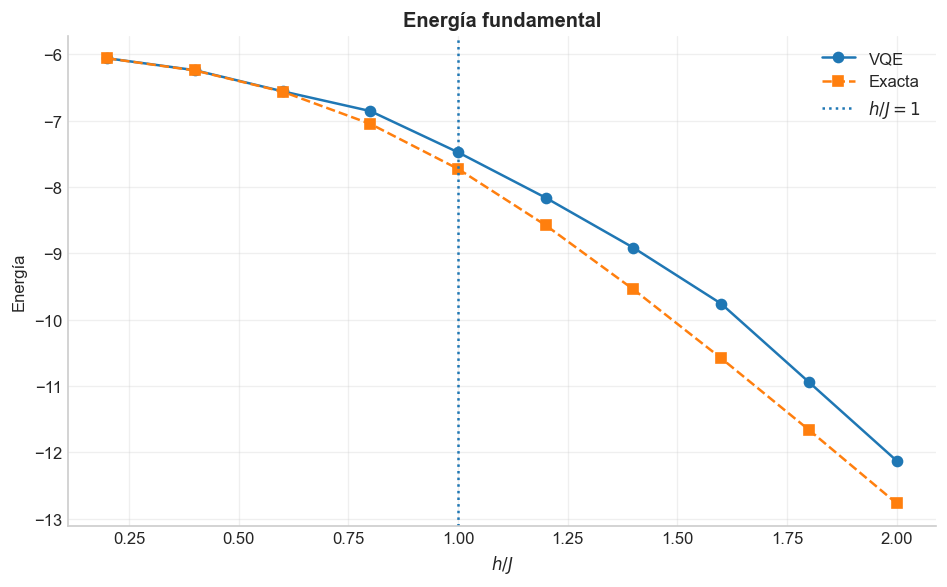

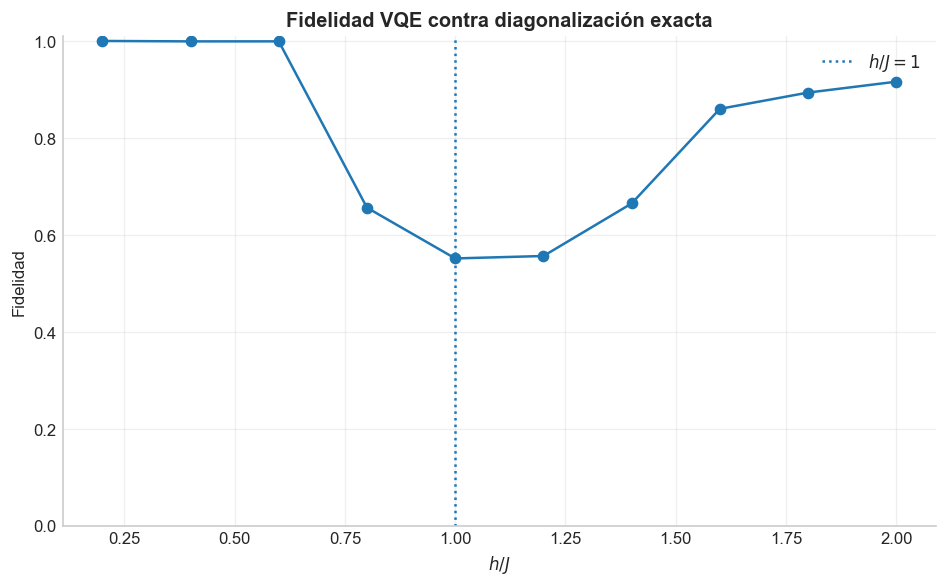

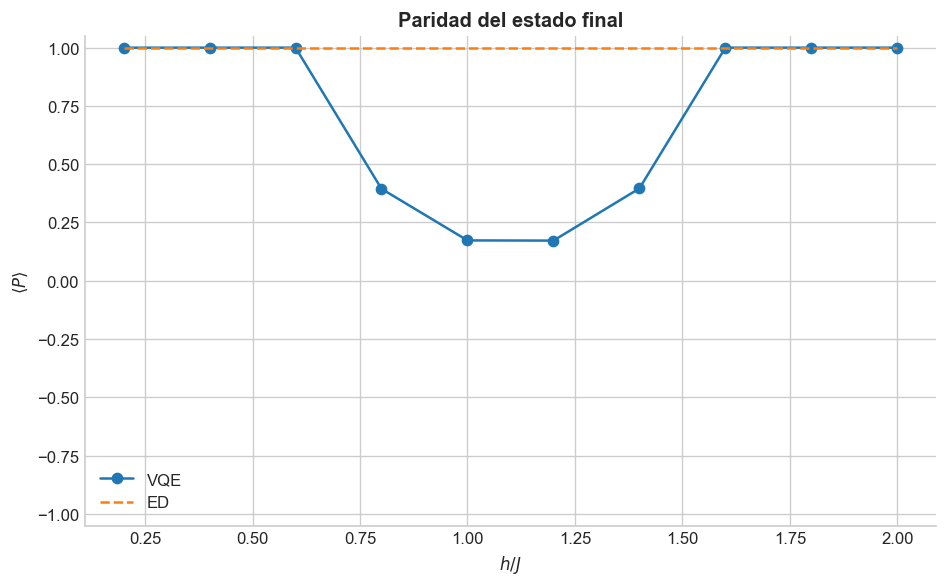

In [4]:
plt.figure(figsize=(8, 5))
plt.plot(
    tabla["h/J"],
    tabla["E_VQE"],
    marker="o",
    label="VQE",
)
plt.plot(
    tabla["h/J"],
    tabla["E_exacta"],
    marker="s",
    linestyle="--",
    label="Exacta",
)
plt.axvline(
    1.0,
    linestyle=":",
    label=r"$h/J=1$",
)
plt.xlabel(r"$h/J$")
plt.ylabel("Energía")
plt.title("Energía fundamental")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(
    tabla["h/J"],
    tabla["fidelidad"],
    marker="o",
)
plt.axvline(
    1.0,
    linestyle=":",
    label=r"$h/J=1$",
)
plt.xlabel(r"$h/J$")
plt.ylabel("Fidelidad")
plt.title("Fidelidad VQE contra diagonalización exacta")
plt.ylim(0.0, 1.01)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(tabla["h/J"], tabla["paridad_VQE"], "o-", label="VQE")
plt.plot(tabla["h/J"], tabla["paridad_ED"], "--", label="ED")
plt.xlabel(r"$h/J$")
plt.ylabel(r"$\langle P\rangle$")
plt.title("Paridad del estado final")
plt.ylim(-1.05, 1.05)
plt.legend()
plt.tight_layout()
plt.show()


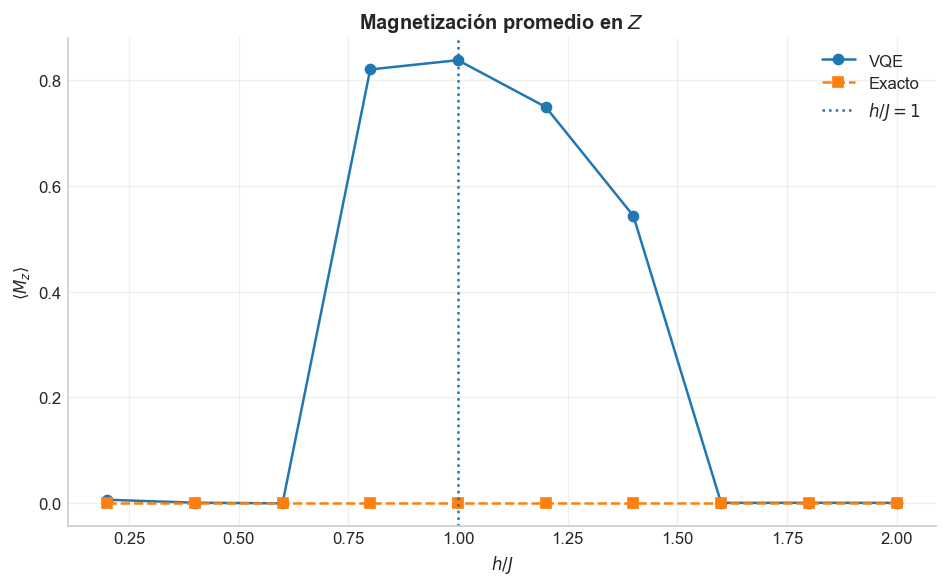

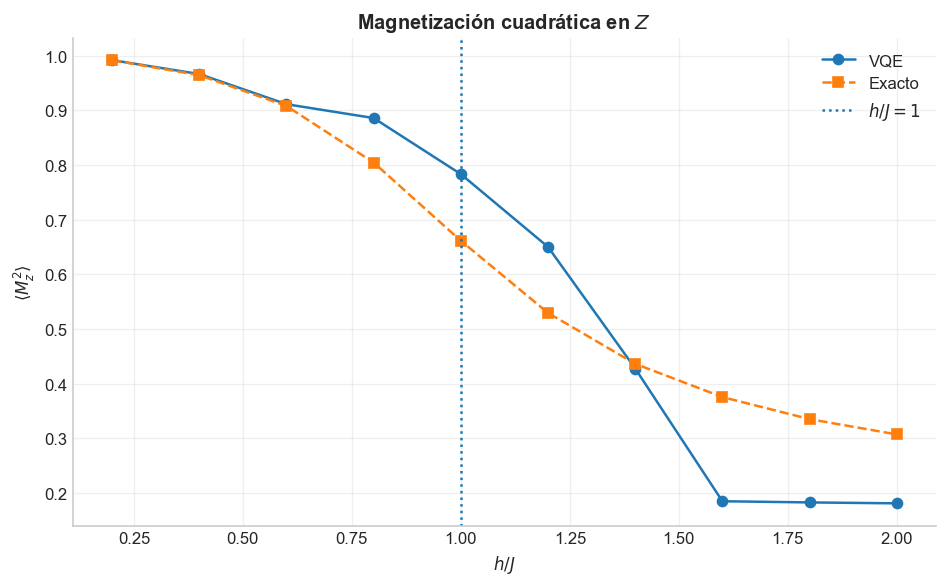

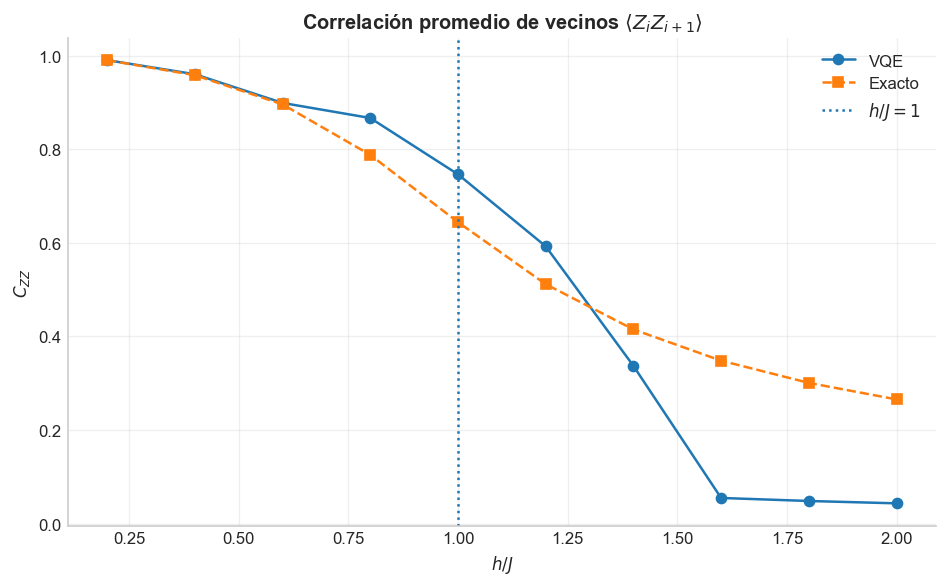

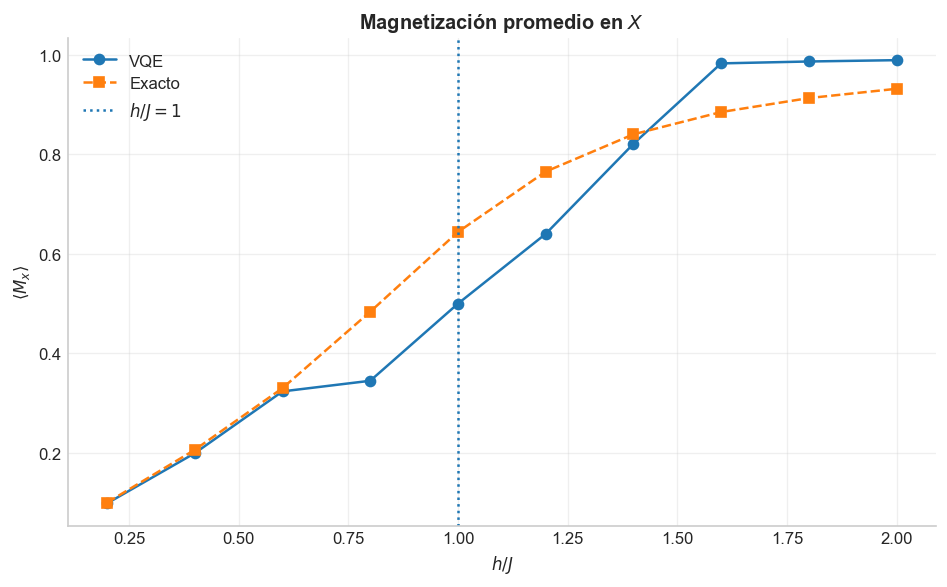

In [5]:
graficas_vqe = [
    ("Mz_VQE", "Mz_exacto", r"$\langle M_z\rangle$", r"Magnetización promedio en $Z$"),
    ("Mz2_VQE", "Mz2_exacto", r"$\langle M_z^2\rangle$", r"Magnetización cuadrática en $Z$"),
    ("Czz_VQE", "Czz_exacto", r"$C_{ZZ}$", r"Correlación promedio de vecinos $\langle Z_iZ_{i+1}\rangle$"),
    ("Mx_VQE", "Mx_exacto", r"$\langle M_x\rangle$", r"Magnetización promedio en $X$"),
]

for columna_vqe, columna_exacta, ylabel, titulo in graficas_vqe:
    plt.figure(figsize=(8, 5))
    plt.plot(
        tabla["h/J"],
        tabla[columna_vqe],
        marker="o",
        label="VQE",
    )
    plt.plot(
        tabla["h/J"],
        tabla[columna_exacta],
        marker="s",
        linestyle="--",
        label="Exacto",
    )
    plt.axvline(
        1.0,
        linestyle=":",
        label=r"$h/J=1$",
    )
    plt.xlabel(r"$h/J$")
    plt.ylabel(ylabel)
    plt.title(titulo)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()


## 6. Comprobación de convergencia: 1600 pasos para campos altos

Repetimos los VQE de $h/J=1.6,1.8,2.0$ desde las mismas inicializaciones y duplicamos el máximo de 800 a 1600 pasos. Se conservan la tasa de aprendizaje, el circuito, la penalización, las semillas y el criterio de parada. Se selecciona el menor costo entre las dos semillas para cada campo.

Los seis entrenamientos se ejecutaron mediante `scripts/reentrenar_tfim_1600.py`. La siguiente celda permite repetirlos; las posteriores analizan los resultados guardados. El barrido inicial de 800 pasos permanece arriba como referencia.


In [ ]:
import subprocess

subprocess.run(
    [sys.executable, str(PROJECT_ROOT / "scripts" / "reentrenar_tfim_1600.py"), "--workers", "3"],
    cwd=PROJECT_ROOT, check=True,
)


In [2]:
tabla_convergencia_1600 = pd.read_csv(
    PROJECT_ROOT / "reports" / "tfim_vqe_convergencia_1600.csv"
)
tabla_semillas_1600 = pd.read_csv(
    PROJECT_ROOT / "reports" / "tfim_vqe_1600" / "resultados_por_semilla.csv"
)
display(tabla_convergencia_1600[[
    "h/J", "fidelidad_800", "fidelidad_1600", "error_E_800", "error_E_1600",
    "paridad_1600", "pasos_1600", "convergio_1600", "norma_gradiente_1600",
]].round(9))
display(tabla_semillas_1600[[
    "h/J", "semilla", "pasos", "convergio", "norma_gradiente",
    "rango_costo_ultimos_100", "max_delta_costo_ultimos_25",
]])


,h/J,fidelidad_800,fidelidad_1600,error_E_800,error_E_1600,paridad_1600,pasos_1600,convergio_1600,norma_gradiente_1600
0,1.6,0.859696,0.859672,0.822096,0.822032,0.999997,1600,False,0.019676
1,1.8,0.893267,0.893285,0.720467,0.720508,0.999991,1600,False,0.040336
2,2.0,0.915768,0.915765,0.642430,0.642533,0.999984,1600,False,0.050159


,h/J,semilla,pasos,convergio,norma_gradiente,rango_costo_ultimos_100,max_delta_costo_ultimos_25
0,1.6,3,1600,False,0.019676,0.000281,0.000051
1,1.6,42,1600,False,0.029058,0.000410,0.000158
2,1.8,3,1600,False,0.056260,0.000491,0.000060
3,1.8,42,1600,False,0.040336,0.000267,0.000067
4,2.0,3,1600,False,0.062484,0.000422,0.000058
5,2.0,42,1600,False,0.050159,0.000428,0.000060


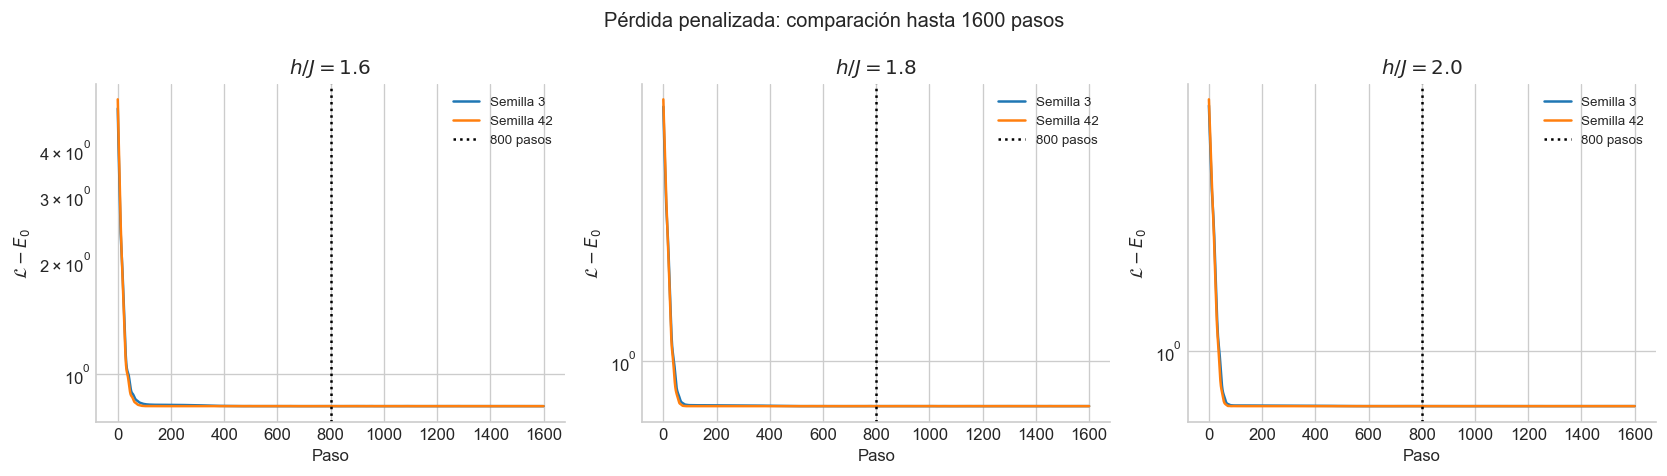

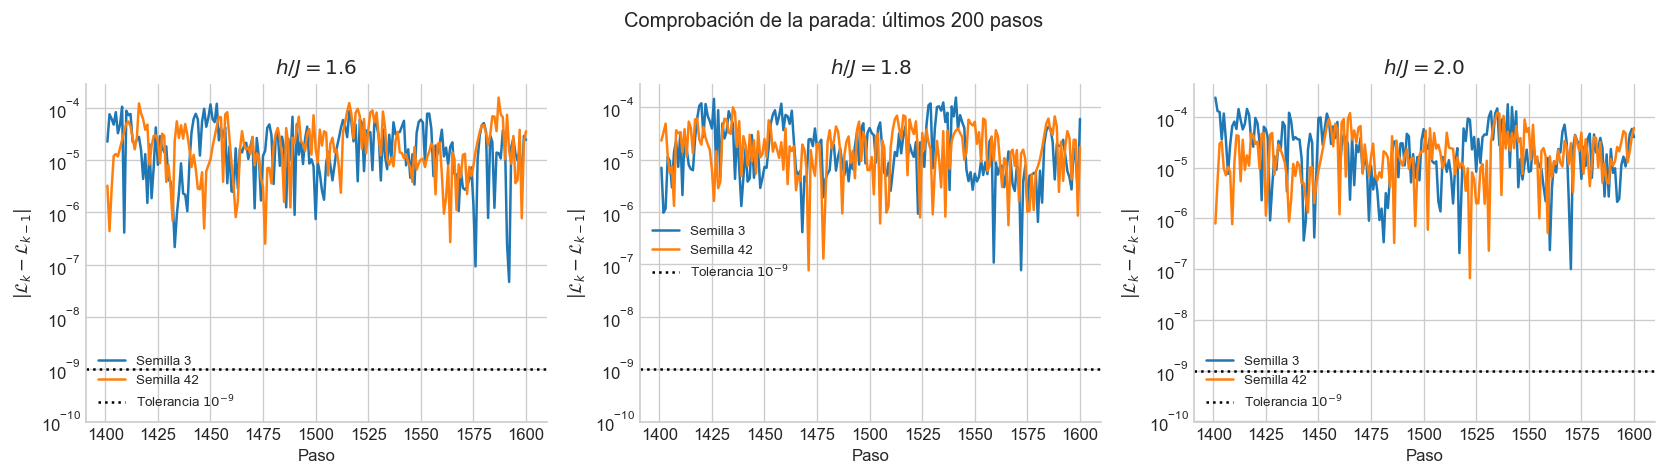

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, h in zip(axes, (1.6, 1.8, 2.0)):
    for seed in (3, 42):
        datos = np.load(PROJECT_ROOT / "reports" / "tfim_vqe_1600" / f"h_{h:.1f}_semilla_{seed}.npz")
        costo = datos["historial_costo"]
        referencia = tabla_semillas_1600.loc[
            np.isclose(tabla_semillas_1600["h/J"], h) & (tabla_semillas_1600["semilla"] == seed)
        ].iloc[0]["E_exacta"]
        ax.semilogy(np.arange(len(costo)), costo - referencia, label=f"Semilla {seed}")
    ax.axvline(800, color="k", ls=":", label="800 pasos")
    ax.set(xlabel="Paso", ylabel=r"$\mathcal{L}-E_0$", title=rf"$h/J={h}$")
    ax.legend(fontsize=8)
fig.suptitle("Pérdida penalizada: comparación hasta 1600 pasos")
fig.tight_layout()
fig.savefig(PROJECT_ROOT / "figures" / "tfim_vqe_1600_perdida.png", dpi=150)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, h in zip(axes, (1.6, 1.8, 2.0)):
    for seed in (3, 42):
        datos = np.load(PROJECT_ROOT / "reports" / "tfim_vqe_1600" / f"h_{h:.1f}_semilla_{seed}.npz")
        costo = datos["historial_costo"]
        cambios = np.abs(np.diff(costo))
        pasos = np.arange(1, len(costo))
        ax.semilogy(pasos[-200:], np.maximum(cambios[-200:], 1e-16), label=f"Semilla {seed}")
    ax.axhline(1e-9, color="k", ls=":", label=r"Tolerancia $10^{-9}$")
    ax.set(xlabel="Paso", ylabel=r"$|\mathcal{L}_k-\mathcal{L}_{k-1}|$", title=rf"$h/J={h}$")
    ax.set_ylim(bottom=1e-10)
    ax.legend(fontsize=8)
fig.suptitle("Comprobación de la parada: últimos 200 pasos")
fig.tight_layout()
fig.savefig(PROJECT_ROOT / "figures" / "tfim_vqe_1600_convergencia.png", dpi=150)
plt.show()


Se repitieron los seis VQE con un máximo de 1600 pasos, manteniendo las semillas `3` y `42`, tres capas, Adam con tasa `0.03` y $\lambda=1$. Los primeros 800 pasos de cada semilla previamente seleccionada coinciden con los historiales guardados del barrido anterior. 0 de las seis corridas cumplieron el criterio de parada $|\mathcal L_k-\mathcal L_{k-1}|<10^{-9}$ durante 25 pasos consecutivos. El cambio máximo de fidelidad entre los resultados seleccionados de 800 y 1600 pasos es $2.39038e-05$. La tabla y las curvas distinguen la estabilidad de la pérdida del criterio de parada.


## 7. Continuación puntual: usar los parámetros de 0.6 para entrenar 0.8

Se ejecuta un único VQE en $h/J=0.8$, inicializado con los parámetros optimizados que ya estaban guardados para $h/J=0.6$. Se mantienen seis espines, tres capas, Adam con tasa $0.03$, hasta 800 pasos, tolerancia $10^{-9}$ durante 25 pasos y penalización de paridad positiva con $\lambda=1$. La referencia de ED se utiliza para evaluar el resultado.

El barrido anterior se conserva para comparar. El optimizador Adam comienza de nuevo; la transferencia corresponde a los parámetros del circuito.

Los resultados se cargan de los archivos guardados; la celda de entrenamiento permite repetir esta prueba.


In [ ]:
# Solo se entrena h/J=0.8; los parámetros de 0.6 se cargan del resultado guardado.
import pennylane as qml

referencia_warm08 = np.load(PROJECT_ROOT / "reports" / "tfim_vqe_paridad_estados.npz", allow_pickle=False)
tabla_previa_warm08 = pd.read_csv(PROJECT_ROOT / "reports" / "tfim_vqe_paridad.csv")
previo_warm08 = tabla_previa_warm08.loc[np.isclose(tabla_previa_warm08["h/J"], 0.8)].iloc[0]
parametros_desde_06 = referencia_warm08["h_0.6_parametros_optimos"].copy()
estado_desde_06 = referencia_warm08["h_0.6_estado_vqe"].copy()
exacto_warm08 = referencia_warm08["h_0.8_estado_exacto"].copy()
print("Inicio desde el VQE guardado de h/J=0.6, semilla de origen 42")
print(f"Fidelidad inicial con el fundamental de 0.8: {abs(np.vdot(exacto_warm08, estado_desde_06)) ** 2:.9f}")

resultado_warm08 = vqe_ising(
    n_qubits=6, J=1.0, h=0.8, n_layers=3,
    learning_rate=0.03, max_steps=800, tol=1e-9, patience=25,
    seed=42, mostrar_cada=100, calcular_exacto=False,
    parametros_iniciales=parametros_desde_06,
    verbose=True, paridad_objetivo=1, peso_paridad=1.0,
)
# Adam se inicializa de nuevo; se transfieren solamente los ángulos del circuito.
np.testing.assert_allclose(
    resultado_warm08["circuito_estado"](parametros_desde_06), estado_desde_06,
    atol=1e-12, rtol=0,
)
estado_warm08 = np.asarray(resultado_warm08["estado_vqe"])
gradiente_warm08 = np.asarray(qml.grad(resultado_warm08["circuito_costo"])(resultado_warm08["parametros_optimos"]))
historial_warm08 = np.asarray(resultado_warm08["historial_costo"])
deltas_warm08 = np.abs(np.diff(historial_warm08))
convergio_warm08 = len(deltas_warm08) >= 25 and bool(np.all(deltas_warm08[-25:] < 1e-9))
fidelidad_warm08 = float(abs(np.vdot(exacto_warm08, estado_warm08)) ** 2)

tabla_warm08 = pd.DataFrame([
    {"caso": "VQE anterior en 0.8", "h/J": 0.8, "pasos": int(previo_warm08["pasos"]),
     "energia": previo_warm08["E_VQE"], "error_E": previo_warm08["error_E"],
     "costo": previo_warm08["costo"], "fidelidad": previo_warm08["fidelidad"], "paridad": previo_warm08["paridad_VQE"]},
    {"caso": "Inicio con parámetros de 0.6", "h/J": 0.8, "pasos": 0,
     "energia": resultado_warm08["historial"][0],
     "error_E": abs(resultado_warm08["historial"][0] - previo_warm08["E_exacta"]),
     "costo": historial_warm08[0], "fidelidad": float(abs(np.vdot(exacto_warm08, estado_desde_06)) ** 2),
     "paridad": resultado_warm08["historial_paridad"][0]},
    {"caso": "0.8 después de continuar desde 0.6", "h/J": 0.8, "pasos": resultado_warm08["pasos_realizados"],
     "energia": resultado_warm08["energia_vqe"],
     "error_E": abs(resultado_warm08["energia_vqe"] - previo_warm08["E_exacta"]),
     "costo": resultado_warm08["costo_vqe"], "fidelidad": fidelidad_warm08,
     "paridad": resultado_warm08["paridad_vqe"]},
])
tabla_warm08.to_csv(PROJECT_ROOT / "reports" / "tfim_vqe_warm_start_08.csv", index=False)
np.savez_compressed(
    PROJECT_ROOT / "reports" / "tfim_vqe_warm_start_08_estados.npz",
    h=0.8, h_origen=0.6, J=1.0, n_qubits=6, n_layers=3, learning_rate=0.03,
    max_steps=800, tol=1e-9, patience=25, paridad_objetivo=1, peso_paridad=1.0,
    semilla_origen=42, parametros_iniciales=parametros_desde_06,
    estado_inicial=estado_desde_06, estado_exacto=exacto_warm08,
    estado_vqe=estado_warm08, parametros_optimos=np.asarray(resultado_warm08["parametros_optimos"]),
    historial=np.asarray(resultado_warm08["historial"]),
    historial_costo=historial_warm08,
    historial_paridad=np.asarray(resultado_warm08["historial_paridad"]),
    gradiente=gradiente_warm08, convergio=convergio_warm08,
)
display(tabla_warm08.round(9))
print(f"Parada por tolerancia: {convergio_warm08}; norma del gradiente: {np.linalg.norm(gradiente_warm08):.6g}")


In [2]:
referencia_warm08 = np.load(PROJECT_ROOT / "reports" / "tfim_vqe_paridad_estados.npz", allow_pickle=False)
tabla_previa_warm08 = pd.read_csv(PROJECT_ROOT / "reports" / "tfim_vqe_paridad.csv")
previo_warm08 = tabla_previa_warm08.loc[np.isclose(tabla_previa_warm08["h/J"], 0.8)].iloc[0]
guardado_warm08 = np.load(PROJECT_ROOT / "reports" / "tfim_vqe_warm_start_08_estados.npz", allow_pickle=False)
tabla_warm08 = pd.read_csv(PROJECT_ROOT / "reports" / "tfim_vqe_warm_start_08.csv")
resultado_warm08 = {
    "historial": guardado_warm08["historial"],
    "historial_paridad": guardado_warm08["historial_paridad"],
}
historial_warm08 = guardado_warm08["historial_costo"]
gradiente_warm08 = guardado_warm08["gradiente"]
convergio_warm08 = bool(guardado_warm08["convergio"])
display(tabla_warm08.round(9))
print(f"Parada por tolerancia: {convergio_warm08}; norma del gradiente: {np.linalg.norm(gradiente_warm08):.6g}")


Parada por tolerancia: False; norma del gradiente: 0.0472359


,caso,h/J,pasos,energia,error_E,costo,fidelidad,paridad
0,VQE anterior en 0.8,0.8,800,-6.855593,0.193211,-6.552777,0.655755,0.394367
1,Inicio con parámetros de 0.6,0.8,0,-6.946376,0.102428,-6.946372,0.958536,0.999992
2,0.8 después de continuar desde 0.6,0.8,800,-7.039027,0.009777,-7.039018,0.998505,0.999981


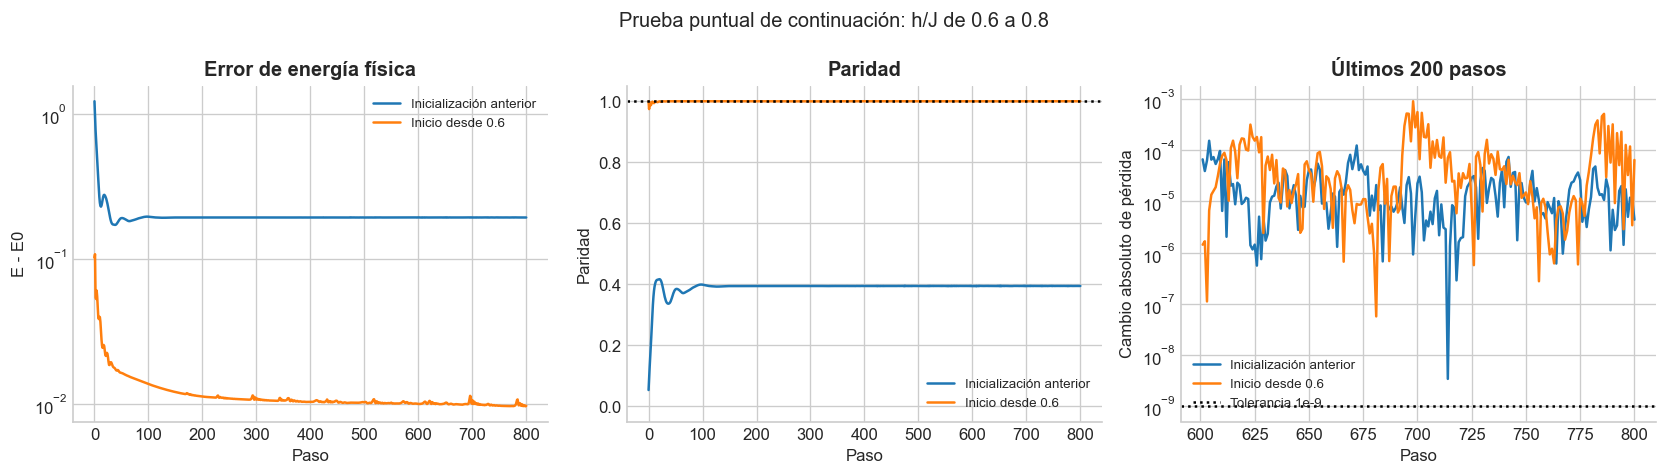

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for etiqueta, energia, costo, paridad in (
    ("Inicialización anterior", referencia_warm08["h_0.8_historial"], referencia_warm08["h_0.8_historial_costo"], referencia_warm08["h_0.8_historial_paridad"]),
    ("Inicio desde 0.6", resultado_warm08["historial"], historial_warm08, resultado_warm08["historial_paridad"]),
):
    pasos = np.arange(len(costo))
    axes[0].semilogy(pasos, np.maximum(np.asarray(energia) - previo_warm08["E_exacta"], 1e-16), label=etiqueta)
    axes[1].plot(pasos, paridad, label=etiqueta)
    cambios = np.abs(np.diff(costo))
    axes[2].semilogy(pasos[1:][-200:], np.maximum(cambios[-200:], 1e-16), label=etiqueta)
axes[0].set(xlabel="Paso", ylabel="E - E0", title="Error de energía física")
axes[1].axhline(1, color="k", ls=":")
axes[1].set(xlabel="Paso", ylabel="Paridad", title="Paridad", ylim=(-0.05, 1.05))
axes[2].axhline(1e-9, color="k", ls=":", label="Tolerancia 1e-9")
axes[2].set(xlabel="Paso", ylabel="Cambio absoluto de pérdida", title="Últimos 200 pasos")
for ax in axes:
    ax.legend(fontsize=8)
fig.suptitle("Prueba puntual de continuación: h/J de 0.6 a 0.8")
fig.tight_layout()
fig.savefig(PROJECT_ROOT / "figures" / "tfim_vqe_warm_start_08.png", dpi=150)
plt.show()


En $h/J=0.8$, la fidelidad pasó de $0.655755$ con la inicialización anterior a $0.998505$ al entrenar desde los parámetros de $0.6$. La paridad final es $0.999981$ y el error de energía es $0.00977703$. Se realizaron 800 pasos. No se alcanzó el criterio de parada por tolerancia; la norma del gradiente final es $0.0472359$. La tabla incluye el estado inicial evaluado en el Hamiltoniano de $0.8$ para distinguir la transferencia inicial del entrenamiento posterior.


## 8. Continuación adaptativa de 1.0 a 2.0

Partimos de los parámetros nuevos de 0.8 y avanzamos en orden por 1.0, 1.2, 1.4, 1.6, 1.8 y 2.0. Cada campo hereda los parámetros finales del anterior. Se conservan seis espines, tres capas, Adam con tasa 0.03 y la penalización de paridad positiva de peso 1.

Revisamos cada 100 pasos y detenemos el campo si la fidelidad supera 0.99. También detenemos por estancamiento cuando, en dos cambios de bloque consecutivos, tanto el cambio absoluto de fidelidad como el cambio absoluto de la pérdida media del bloque son menores que 0.0001. El máximo es 800 pasos por campo.

Adam conserva sus momentos entre los bloques del mismo campo y comienza de nuevo al cambiar de campo. Tras estancarse o alcanzar el límite también se avanza al siguiente campo, dejando explícito si se logró el objetivo de fidelidad. La fidelidad con ED se utiliza para comprobar la parada; la función de costo sigue siendo energía más penalización de paridad.

El entrenamiento se ejecutó con el script indicado abajo. Las celdas posteriores muestran los resultados guardados.


In [ ]:
import subprocess

subprocess.run(
    [sys.executable, str(PROJECT_ROOT / "scripts" / "continuar_tfim_adaptativo.py")],
    cwd=PROJECT_ROOT, check=True,
)


In [2]:
tabla_adaptativa = pd.read_csv(PROJECT_ROOT / "reports" / "tfim_vqe_continuacion_adaptativa.csv")
bloques_adaptativos = pd.read_csv(PROJECT_ROOT / "reports" / "tfim_vqe_continuacion_adaptativa" / "bloques.csv")
display(tabla_adaptativa[[
    "h/J", "h_origen", "fidelidad_anterior", "fidelidad_inicial", "fidelidad",
    "pasos", "motivo_parada", "paridad", "error_E",
]].round(9))
display(bloques_adaptativos[[
    "h/J", "paso", "fidelidad", "costo_medio", "delta_fidelidad_abs",
    "delta_costo_medio_abs", "bloques_estables", "motivo",
]])


,h/J,h_origen,fidelidad_anterior,fidelidad_inicial,fidelidad,pasos,motivo_parada,paridad,error_E
0,1.0,0.8,0.551053,0.955703,0.997967,100,fidelidad_objetivo,0.999999,0.014043
1,1.2,1.0,0.556062,0.970735,0.998219,100,fidelidad_objetivo,0.999999,0.012284
2,1.4,1.2,0.664466,0.986434,0.998818,100,fidelidad_objetivo,1.000000,0.008603
3,1.6,1.4,0.859696,0.993628,0.999274,100,fidelidad_objetivo,1.000000,0.005686
4,1.8,1.6,0.893267,0.996739,0.999561,100,fidelidad_objetivo,1.000000,0.003768
5,2.0,1.8,0.915768,0.998141,0.999728,100,fidelidad_objetivo,1.000000,0.002562


,h/J,paso,fidelidad,costo_medio,delta_fidelidad_abs,delta_costo_medio_abs,bloques_estables,motivo
0,1.0,100,0.997967,-7.706369,NaN,NaN,0,fidelidad_objetivo
1,1.2,100,0.998219,-8.559133,NaN,NaN,0,fidelidad_objetivo
2,1.4,100,0.998818,-9.530919,NaN,NaN,0,fidelidad_objetivo
3,1.6,100,0.999274,-10.570601,NaN,NaN,0,fidelidad_objetivo
4,1.8,100,0.999561,-11.651516,NaN,NaN,0,fidelidad_objetivo
5,2.0,100,0.999728,-12.760458,NaN,NaN,0,fidelidad_objetivo


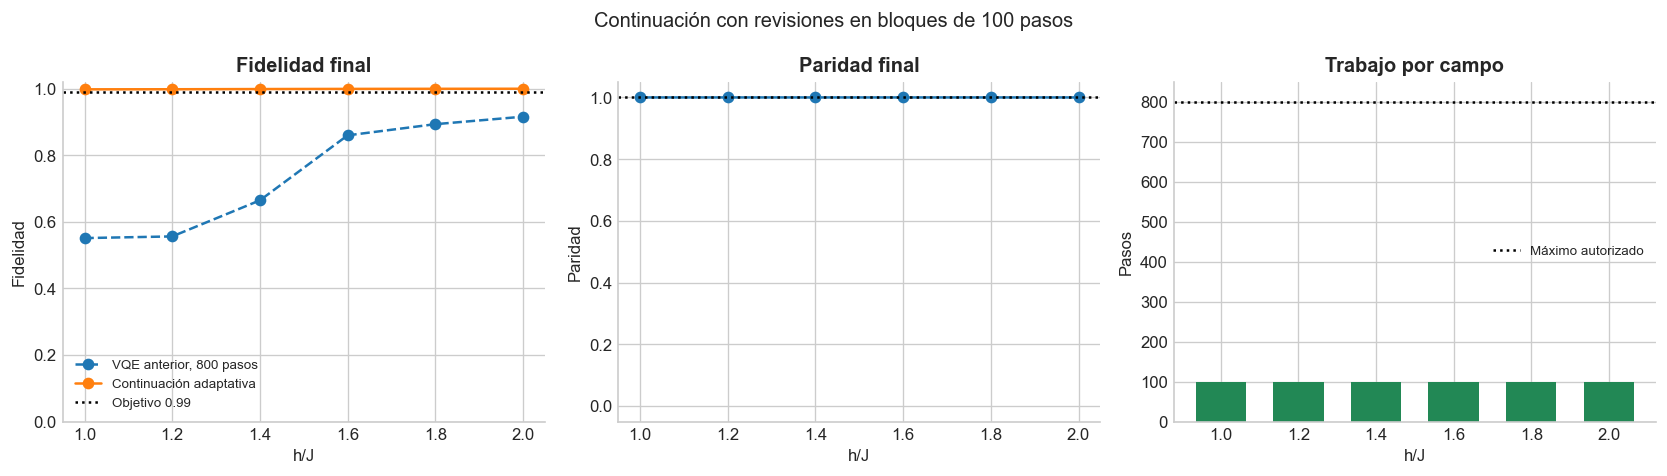

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
x = tabla_adaptativa["h/J"]
axes[0].plot(x, tabla_adaptativa["fidelidad_anterior"], "o--", label="VQE anterior, 800 pasos")
axes[0].plot(x, tabla_adaptativa["fidelidad"], "o-", label="Continuación adaptativa")
axes[0].axhline(0.99, color="k", ls=":", label="Objetivo 0.99")
axes[0].set(xlabel="h/J", ylabel="Fidelidad", title="Fidelidad final", ylim=(0, 1.02))
axes[0].legend(fontsize=8)
axes[1].plot(x, tabla_adaptativa["paridad"], "o-")
axes[1].axhline(1.0, color="k", ls=":")
axes[1].set(xlabel="h/J", ylabel="Paridad", title="Paridad final", ylim=(-0.05, 1.05))
colors = tabla_adaptativa["objetivo_cumplido"].map({True: "#228855", False: "#cc6633"})
axes[2].bar(x, tabla_adaptativa["pasos"], width=0.13, color=colors)
axes[2].axhline(800, color="k", ls=":", label="Máximo autorizado")
axes[2].set(xlabel="h/J", ylabel="Pasos", title="Trabajo por campo", ylim=(0, 850), xticks=x)
axes[2].legend(fontsize=8)
fig.suptitle("Continuación con revisiones en bloques de 100 pasos")
fig.tight_layout()
fig.savefig(PROJECT_ROOT / "figures" / "tfim_vqe_continuacion_adaptativa.png", dpi=150)
plt.show()


6 de los seis campos superaron el 99 % de fidelidad. Se utilizaron 600 pasos en total, frente a 4800 si se hubieran impuesto 800 pasos en cada campo. Las causas de parada y las revisiones de cada bloque se guardan en `reports/tfim_vqe_continuacion_adaptativa.csv` y `reports/tfim_vqe_continuacion_adaptativa/bloques.csv`. Los estados, parámetros iniciales y finales e historiales de cada campo se conservan en `reports/tfim_vqe_continuacion_adaptativa/`.


## Conclusiones y alcance de los resultados

1. Reducir el paso de Trotter mejora la fidelidad frente a ED; con un paso fijo, el error crece con el número de espines.
2. El costo de paridad favorece el sector positivo del TFIM, pero la inicialización del circuito también influyó sustancialmente en el resultado.
3. La propuesta de Benjamín de transferir parámetros entre campos cercanos se comprobó primero en 0.6 → 0.8 y luego en la continuación hasta 2.0.
4. Los diez puntos consolidados superan 99 % de fidelidad. Los seis campos de 1.0–2.0 alcanzaron el objetivo en 100 pasos cada uno, con paridad prácticamente positiva.
5. La parada por estancamiento quedó implementada y probada; no se activó en estos seis casos. Los criterios y causas de parada se registran por bloque.
6. La fidelidad objetivo de este benchmark utiliza la referencia de ED; el costo del entrenamiento sigue siendo energía más penalización. El objetivo de precisión se distingue de la convergencia estricta de Adam.
7. En seis espines el cambio de régimen es suave. Mx, Mz² y Czz se guardan junto con las referencias exactas para revisar su comportamiento.
8. Los resultados son de simulación ideal, sin ruido, y no establecen ventaja cuántica.

El informe de la entrega original se complementa con [la bitácora del 15 de noviembre de 2026](../reports/bitacora_tfim_2026-11-15.md).
